# Data Prep

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, LeaveOneGroupOut
from sklearn.metrics import r2_score


In [29]:
raw = pd.read_excel('Rushing_Yards_Total_2015_2025.xlsx', header=None)
raw.shape

(22, 69)

In [30]:
row0 = raw.iloc[0]
season_blocks = []
for c in range(raw.shape[1]):
    val = row0[c]
    if pd.notna(val):
        season_blocks.append((c, int(val)))

print(season_blocks)

[(0, 2016), (7, 2017), (14, 2018), (21, 2019), (28, 2020), (35, 2021), (42, 2022), (49, 2023), (56, 2024), (63, 2025)]


In [31]:
records = []
for c0, target_season in season_blocks:
    for r in range(2, raw.shape[0]):
        player = raw.iloc[r, c0]
        if pd.isna(player):
            continue
        records.append({
            "Player": player,
            "Selection_Season": raw.iloc[r, c0+1],
            "Selection_Season_Games_Played": raw.iloc[r, c0+2],
            "Selection_Season_Rush_Yards": raw.iloc[r, c0+3],
            "Target_Season": target_season,
            "Target_Week1_2_Rush_Yards": raw.iloc[r, c0+4],
            "Target_Final_Rush_Yards": raw.iloc[r, c0+5],
        })

rb_long = pd.DataFrame(records)
rb_long.shape

(194, 7)

In [32]:
rb_long.isna().sum()

Player                           0
Selection_Season                 0
Selection_Season_Games_Played    0
Selection_Season_Rush_Yards      0
Target_Season                    0
Target_Week1_2_Rush_Yards        0
Target_Final_Rush_Yards          0
dtype: int64

In [33]:
rb_long.duplicated(subset=["Player","Target_Season"]).sum()

np.int64(0)

In [34]:
(rb_long["Selection_Season_Games_Played"] < 10).sum()

np.int64(0)

In [35]:
rb_long = rb_long.sort_values(["Target_Season", "Player"]).reset_index(drop=True)
rb_long.to_csv('rb_training_pool.csv', index=False)

rb_long

,Player,Selection_Season,Selection_Season_Games_Played,Selection_Season_Rush_Yards,Target_Season,Target_Week1_2_Rush_Yards,Target_Final_Rush_Yards
0,A. Peterson,2015,16,1485,2016,40,72
1,C. Ivory,2015,15,1070,2016,43,439
2,C. Johnson,2015,11,814,2016,56,95
3,D. Freeman,2015,15,1061,2016,113,1079
4,D. Martin,2015,16,1402,2016,85,421
...,...,...,...,...,...,...,...
189,K. Williams,2024,16,1299,2025,132,1252
190,N. Harris,2024,17,1043,2025,33,61
191,R. Dowdle,2024,16,1079,2025,21,1076
192,S. Barkley,2024,16,2005,2025,148,1140


# EDA

In [36]:
rb_long[["Selection_Season_Rush_Yards", "Target_Week1_2_Rush_Yards", "Target_Final_Rush_Yards"]].describe()

,Selection_Season_Rush_Yards,Target_Week1_2_Rush_Yards,Target_Final_Rush_Yards
count,194.000000,194.000000,194.000000
mean,1072.994845,107.932990,783.422680
std,223.472721,54.429692,438.075876
min,758.000000,0.000000,0.000000
25%,914.250000,69.000000,433.750000
50%,1029.500000,107.000000,821.500000
75%,1148.500000,142.000000,1069.250000
max,2027.000000,268.000000,2027.000000


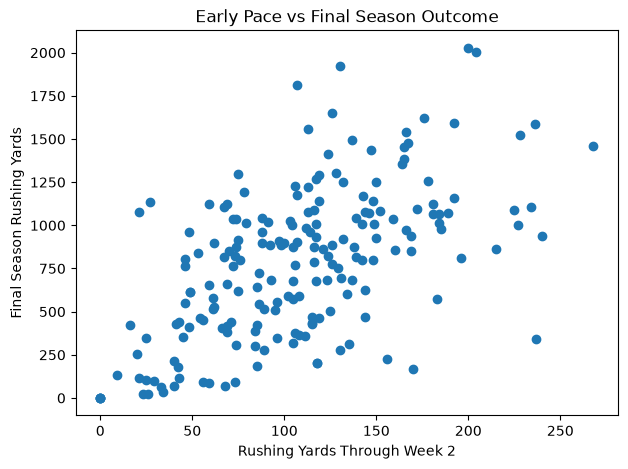

In [37]:
plt.figure(figsize=(7,5))
plt.scatter(rb_long["Target_Week1_2_Rush_Yards"], rb_long["Target_Final_Rush_Yards"])
plt.xlabel("Rushing Yards Through Week 2")
plt.ylabel("Final Season Rushing Yards")
plt.title("Early Pace vs Final Season Outcome")
plt.show()

In [38]:
rb_long[["Target_Week1_2_Rush_Yards", "Target_Final_Rush_Yards"]].corr()

,Target_Week1_2_Rush_Yards,Target_Final_Rush_Yards
Target_Week1_2_Rush_Yards,1.000000,0.579529
Target_Final_Rush_Yards,0.579529,1.000000


In [39]:
X = rb_long[['Target_Week1_2_Rush_Yards']]
y = rb_long['Target_Final_Rush_Yards']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)

y_pred = model.predict(X_test)

results_df = pd.DataFrame({
    "Actual Rushing Yards": y_test,
    "Predicted Rushing Yards": y_pred
})

results_df

,Actual Rushing Yards,Predicted Rushing Yards
138,694,875.459835
16,131,308.729692
155,876,805.779899
96,34,424.862918
68,525,554.932131
153,1008,810.425228
55,578,550.286802
15,1043,675.710686
112,386,657.129370
111,254,359.828312


In [40]:
model_df_rb = rb_long[["Target_Week1_2_Rush_Yards", "Target_Final_Rush_Yards", "Player"]].dropna()

X = model_df_rb[["Target_Week1_2_Rush_Yards"]].values
y = model_df_rb["Target_Final_Rush_Yards"].values
groups = model_df_rb["Player"].values

In [41]:
model_df_rb["Player"].value_counts()

Player
E. Elliott       6
D. Henry         6
T. Gurley        5
M. Gordon III    5
A. Kamara        5
                ..
R. White         1
B. Irving        1
C. Brown         1
K. Williams      1
R. Dowdle        1
Name: count, Length: 97, dtype: int64

# Statistical Analysis
## Single Predictor Models

In [42]:
logo = LeaveOneGroupOut()
preds = np.zeros(len(y))

for train_idx, test_idx in logo.split(X, y, groups):
    model = LinearRegression()
    model.fit(X[train_idx], y[train_idx])
    preds[test_idx] = model.predict(X[test_idx])

rb_r2 = r2_score(y, preds)
print("Rushing pace → Final yards, LOCO-CV R²:", rb_r2)

Rushing pace → Final yards, LOCO-CV R²: 0.32139009787146233


In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
naive_model = LinearRegression().fit(X_train, y_train)
naive_r2 = r2_score(y_test, naive_model.predict(X_test))
print("Naive train/test R²:", naive_r2)

Naive train/test R²: 0.3348814028947178


In [44]:
final_model = LinearRegression().fit(X, y)
print("Intercept:", final_model.intercept_)
print("Coefficient:", final_model.coef_[0])

Intercept: 279.9881108505905
Coefficient: 4.664325254070655


# Visualization

In [45]:
intercept = final_model.intercept_
coef = final_model.coef_[0]

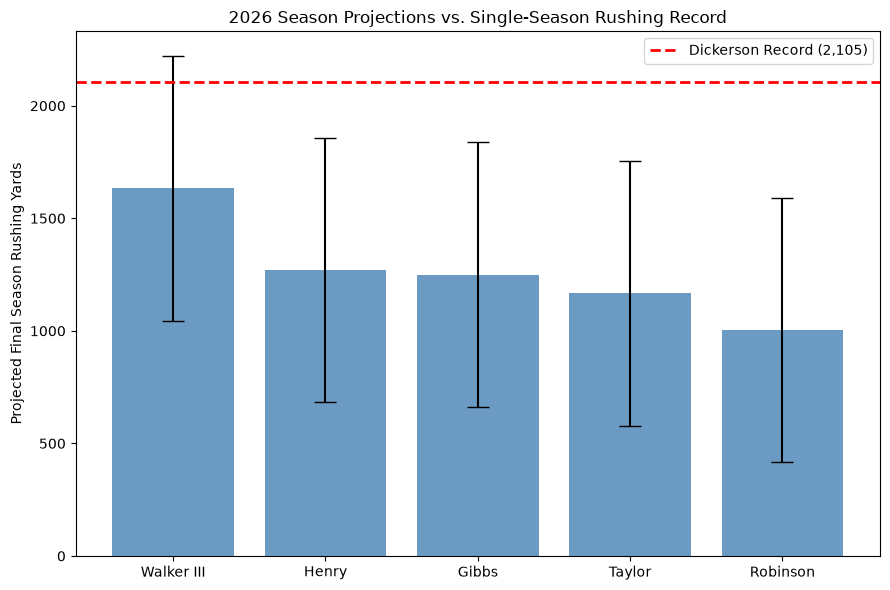

In [46]:
players = {
    "Walker III": 290,
    "Henry": 212,
    "Gibbs": 208,
    "Taylor": 190,
    "Robinson": 155,
}

names = list(players.keys())
week2_yards = list(players.values())
projections = [intercept + coef * w for w in week2_yards]

# Residual SD from the fitted model itself, not a hard-coded number:
# residuals on the full training data (X, y from the model above),
# divided by n - 2 (two fitted parameters: intercept and slope).
# This updates automatically if the training data or model changes.
residuals = y - final_model.predict(X)
resid_std = float(np.sqrt(np.sum(residuals ** 2) / (len(y) - 2)))

fig, ax = plt.subplots(figsize=(9, 6))

# bar for each player's point projection
ax.bar(names, projections, color="steelblue", alpha=0.8)

# error bars showing the ~90% uncertainty range (±1.64 * resid_std)
ax.errorbar(names, projections, yerr=1.64*resid_std, fmt="none", ecolor="black", capsize=8, linewidth=1.5)

# Dickerson's record as a horizontal reference line
ax.axhline(2105, color="red", linestyle="--", linewidth=2, label="Dickerson Record (2,105)")

ax.set_ylabel("Projected Final Season Rushing Yards")
ax.set_title("2026 Season Projections vs. Single-Season Rushing Record")
ax.legend()
plt.tight_layout()
plt.show()


In [47]:
henry_weeks =       [1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
henry_cumulative =  [116, 200, 319, 376, 588, 663, 775, 843, 946, 1079, 1257, 1317, 1532, 1679, 1777, 2027]

In [48]:
walker_weeks = [1, 2]
walker_cumulative = [173, 290]

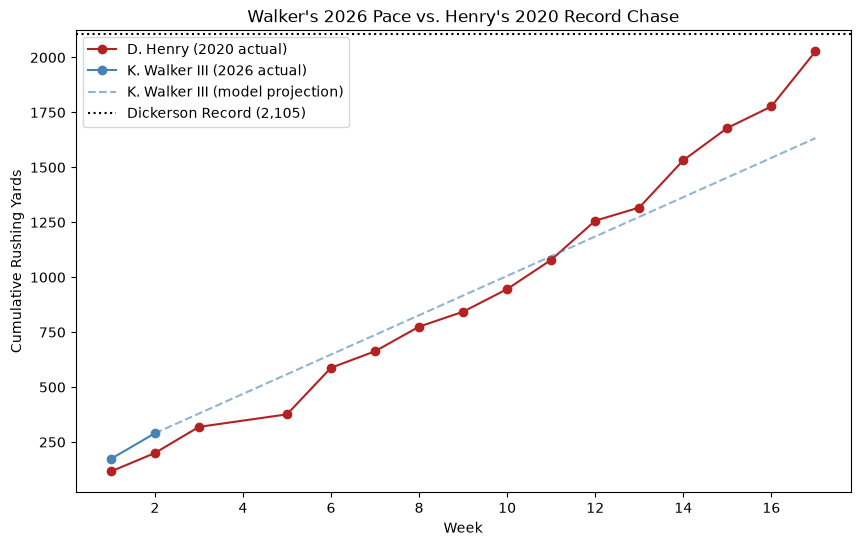

In [49]:
plt.figure(figsize=(10, 6))

# Henry's real, complete trajectory
plt.plot(henry_weeks, henry_cumulative, marker="o", color="firebrick", label="D. Henry (2020 actual)")

# Walker's real trajectory so far
plt.plot(walker_weeks, walker_cumulative, marker="o", color="steelblue", label="K. Walker III (2026 actual)")

# Walker's projected continuation, using your model's actual projection (not naive pace extrapolation)
walker_projected_final = intercept + coef * walker_cumulative[-1]
plt.plot([2, 17], [290, walker_projected_final], linestyle="--", color="steelblue", alpha=0.6, label="K. Walker III (model projection)")

plt.axhline(2105, color="black", linestyle=":", label="Dickerson Record (2,105)")

plt.xlabel("Week")
plt.ylabel("Cumulative Rushing Yards")
plt.title("Walker's 2026 Pace vs. Henry's 2020 Record Chase")
plt.legend()
plt.show()

In [50]:
dickerson_weeks =      [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
dickerson_cumulative = [138, 240, 289, 378, 498, 605, 780, 925, 963, 1171, 1320, 1452, 1643, 1792, 2007, 2105]

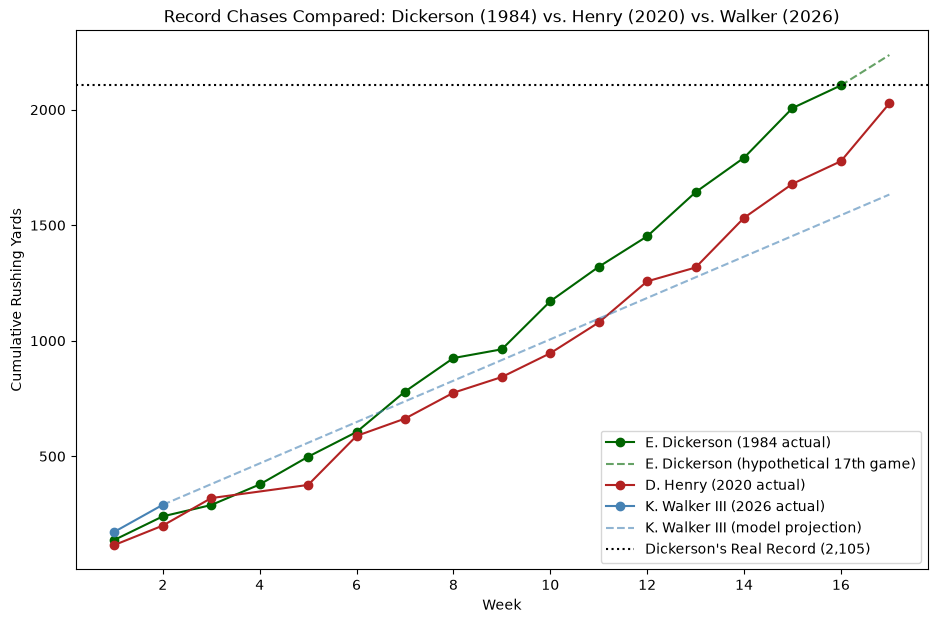

In [51]:
plt.figure(figsize=(11, 7))

plt.plot(dickerson_weeks, dickerson_cumulative, marker="o", color="darkgreen", label="E. Dickerson (1984 actual)")
plt.plot([16, 17], [2105, 2236.6], linestyle="--", color="darkgreen", alpha=0.6, label="E. Dickerson (hypothetical 17th game)")

plt.plot(henry_weeks, henry_cumulative, marker="o", color="firebrick", label="D. Henry (2020 actual)")

plt.plot(walker_weeks, walker_cumulative, marker="o", color="steelblue", label="K. Walker III (2026 actual)")
plt.plot([2, 17], [290, walker_projected_final], linestyle="--", color="steelblue", alpha=0.6, label="K. Walker III (model projection)")

plt.axhline(2105, color="black", linestyle=":", label="Dickerson's Real Record (2,105)")

plt.xlabel("Week")
plt.ylabel("Cumulative Rushing Yards")
plt.title("Record Chases Compared: Dickerson (1984) vs. Henry (2020) vs. Walker (2026)")
plt.legend()
plt.show()

# 2026 Weekly Tracking
## Load Weekly Data

In [52]:
weekly = pd.read_excel('NFL_RB_2026_Weekly_Tracking.xlsx',
                       sheet_name='Weekly_Rushing_2026', header=[0, 1])

backs = ['K. Walker III', 'D. Henry', 'J. Gibbs', 'J. Taylor', 'B. Robinson']

records = []
for back in backs:
    # "BYE" or blank -> NaN and skipped below. A real 0-yard game counts as played,
    # so use BYE (not 0) when a back was out / did not play, e.g. Walker Weeks 10-12.
    yards = pd.to_numeric(weekly[(back, 'Rush_Yards')], errors='coerce')   # "BYE" -> NaN
    for week, y in zip(weekly.iloc[:, 0], yards):
        if pd.notna(y):                      # skip weeks not played yet and bye weeks
            records.append({'Player': back, 'Week': week, 'Rush_Yards': y})

rb_2026 = pd.DataFrame(records)
rb_2026['Cumulative_Yards'] = rb_2026.groupby('Player')['Rush_Yards'].cumsum()
rb_2026['Games_Played']     = rb_2026.groupby('Player').cumcount() + 1
rb_2026['Pace_17_Games']    = rb_2026['Cumulative_Yards'] / rb_2026['Games_Played'] * 17

print(rb_2026.shape)
print(rb_2026.groupby('Player').tail(1))

(51, 6)
           Player  Week  Rush_Yards  Cumulative_Yards  Games_Played  \
7   K. Walker III     9       102.0             872.0             8   
18       D. Henry    11        94.0             793.0            11   
29       J. Gibbs    12       205.0            1303.0            11   
40      J. Taylor    11        21.0             760.0            11   
50    B. Robinson    10        71.0             951.0            10   

    Pace_17_Games  
7     1853.000000  
18    1225.545455  
29    2013.727273  
40    1174.545455  
50    1616.700000  


## Actual Pace vs Model Projection

In [53]:
week12 = rb_2026[rb_2026['Week'] <= 2].groupby('Player')['Rush_Yards'].sum()

proj = pd.Series(
    final_model.predict(week12.values.reshape(-1, 1)),
    index=week12.index
)

latest = rb_2026.groupby('Player').tail(1).set_index('Player')

compare = pd.DataFrame({
    'Week1_2_Yards':   week12,
    'Projected_Final': proj.round(1),
    'Cumulative_Now':  latest['Cumulative_Yards'],
    'Pace_17_Games':   latest['Pace_17_Games'],
})
compare['Pace_Minus_Projection'] = compare['Pace_17_Games'] - compare['Projected_Final']

print(compare.sort_values('Projected_Final', ascending=False))

               Week1_2_Yards  Projected_Final  Cumulative_Now  Pace_17_Games  \
Player                                                                         
K. Walker III          290.0           1632.6           872.0    1853.000000   
D. Henry               212.0           1268.8           793.0    1225.545455   
J. Gibbs               208.0           1250.2          1303.0    2013.727273   
J. Taylor              190.0           1166.2           760.0    1174.545455   
B. Robinson            155.0           1003.0           951.0    1616.700000   

               Pace_Minus_Projection  
Player                                
K. Walker III             220.400000  
D. Henry                  -43.254545  
J. Gibbs                  763.527273  
J. Taylor                   8.345455  
B. Robinson               613.700000  


## Required Pace for the Rest of the Season

In [54]:
compare['Games_Left'] = 17 - latest['Games_Played']

compare['Need_Per_Game_For_Projection'] = (compare['Projected_Final'] - compare['Cumulative_Now']) / compare['Games_Left']
compare['Need_Per_Game_For_Record']     = (2105 - compare['Cumulative_Now']) / compare['Games_Left']

print(compare[['Cumulative_Now', 'Games_Left',
               'Need_Per_Game_For_Projection', 'Need_Per_Game_For_Record']].round(1))

               Cumulative_Now  Games_Left  Need_Per_Game_For_Projection  \
Player                                                                    
B. Robinson             951.0           7                           7.4   
D. Henry                793.0           6                          79.3   
J. Gibbs               1303.0           6                          -8.8   
J. Taylor               760.0           6                          67.7   
K. Walker III           872.0           9                          84.5   

               Need_Per_Game_For_Record  
Player                                   
B. Robinson                       164.9  
D. Henry                          218.7  
J. Gibbs                          133.7  
J. Taylor                         224.2  
K. Walker III                     137.0  


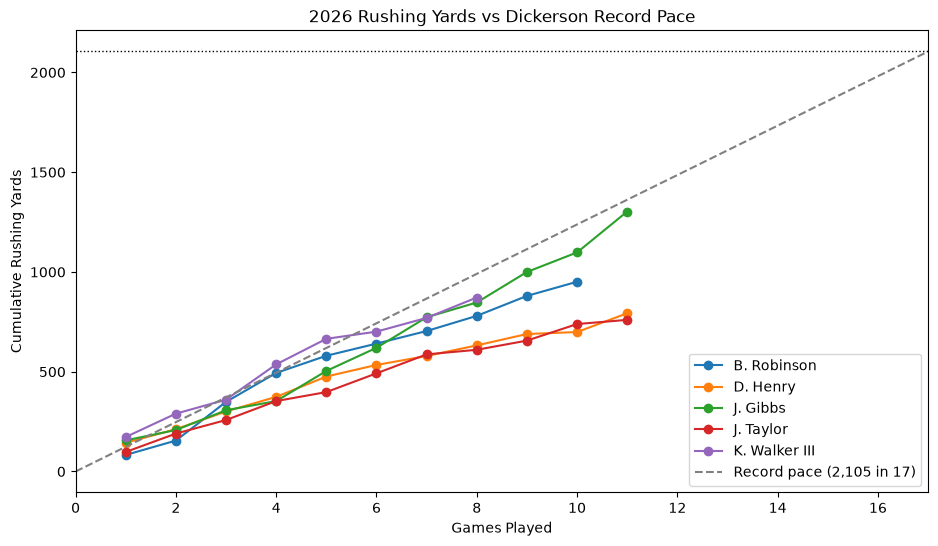

In [55]:
plt.figure(figsize=(11, 6))

for back, g in rb_2026.groupby('Player'):
    plt.plot(g['Games_Played'], g['Cumulative_Yards'], marker='o', label=back)

games = np.arange(0, 18)
plt.plot(games, 2105 * games / 17, linestyle='--', color='gray', label='Record pace (2,105 in 17)')

plt.axhline(2105, linestyle=':', color='black', linewidth=1)
plt.xlim(0, 17)
plt.xlabel('Games Played')
plt.ylabel('Cumulative Rushing Yards')
plt.title('2026 Rushing Yards vs Dickerson Record Pace')
plt.legend()
plt.show()